# Exercise 2: Solving a Search Problem with a Quantum Computer (Template)

In computer science, satisfiability problems are known to be difficult to solve (often NP-Hard, no polynomial time algorithms). 
A satisfiability problem generally refers to finding a solution(s) that satisfy the logical conjuntion ("AND") of multiple propositions.
For example, 3-SAT problem, a widely known NP-Hard problem, refers to the conjunction of multiple disjunctions ("OR") of 3 elements 
(e.g., $(a_{1} \lor b_{1} \lor c_{1}) \land (a_{2} \lor b_{2} \lor c_{2}) \land \ldots \land (a_{N} \lor b_{N} \lor c_{N})$).

We are going to encode a short 3-SAT problem using `revkit` and solve it using Qiskit.

In [1]:
import qiskit
import matplotlib
import altair as alt
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime.fake_provider import FakeSherbrooke

from revkit import netlist, oracle_synth, truth_table
import revkit.export.qiskit

## Step 1. Write your 3-SAT problem

We are first going to write a 3-SAT problem.
The below expression means: $(a \lor b \lor \lnot c) \land (\lnot b \lor c \lor d)$

In [194]:
logic = ""

Getting the number of logical symbols (letters)

In [195]:
letters = "abcdefghijklmnopqrstuvwxyz"
def get_n_symbols(_logic):
    count = 0
    for l in letters:
        if l in _logic:
            count = count + 1
    return count

In [196]:
n_logic_qubis = get_n_symbols(logic)
n_logic_qubis

4

### Step 1-1. A logic expression $\rightarrow$ an oracle gate

In [211]:
function = 
oracle = 
oracle_gate = 
oracle_gate.name = logic

Drawing the circuit

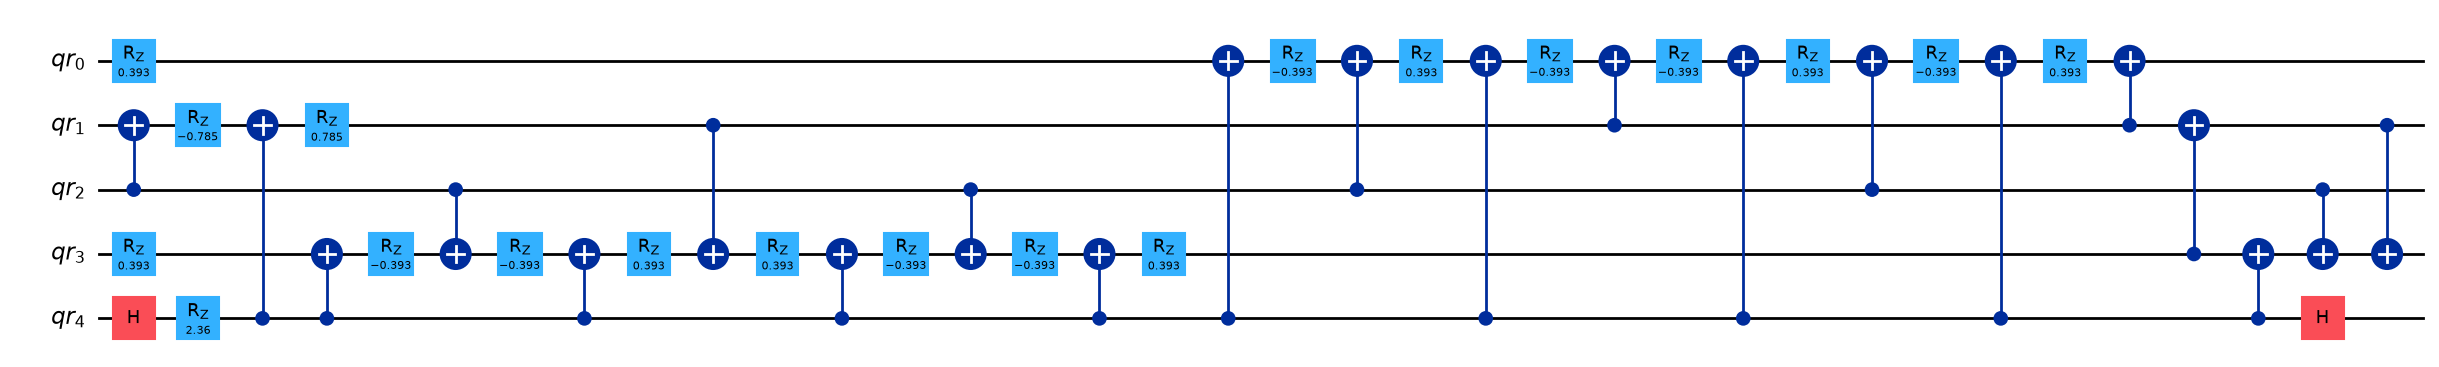

In [199]:
oracle_gate.draw("mpl", fold=60)

### Step 1-2. Building a logical quantum circuit
We need to add Hadamard gates for randomization and measurements. 

In [200]:
# N logic qubits + 1 control qubit
n_qubits = ?
qc = 
# h
# add
# measure

Drawing the final circuit.

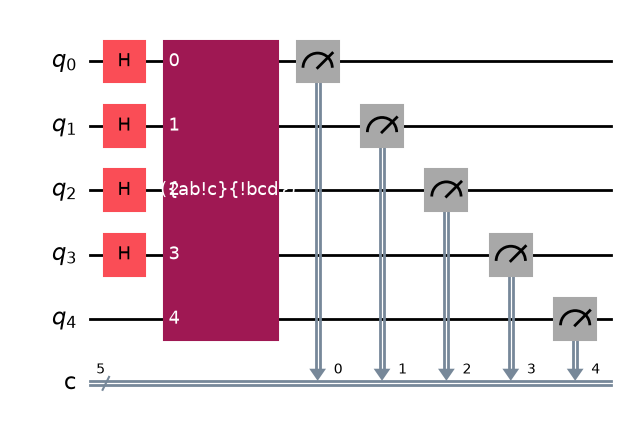

In [201]:
qc.draw("mpl", fold=60)

## Step 2. Run the circuit on a simulator

### Step 2-1. Set up a fake machine and transpile the circuit

In [218]:
backend_fake = 
pass_manager_sim =
transpiled_qc_sim  = 
job_sim = 

### Step 2-2. Get results

In [219]:
result_sim = 

{'11000': 43,
 '01100': 26,
 '01011': 62,
 '00000': 52,
 '00010': 37,
 '00011': 49,
 '00111': 63,
 '10100': 42,
 '01111': 52,
 '01110': 47,
 '10011': 210,
 '00101': 44,
 '10101': 175,
 '00100': 194,
 '01000': 187,
 '10001': 191,
 '00001': 50,
 '11010': 207,
 '11111': 234,
 '11101': 223,
 '00110': 220,
 '10110': 65,
 '11011': 194,
 '01001': 182,
 '01010': 53,
 '01101': 33,
 '10111': 238,
 '11100': 183,
 '10010': 203,
 '11110': 215,
 '11001': 47,
 '10000': 179}

### Step 2-3. Use Patoka visualization

In [223]:
import json
from patoka import getResultViewer, processSimJobData
from IPython.display import display

viewer_sim = getResultViewer()

In [224]:
display(viewer_sim)

#### Stream the data
Why? In many cases, the data is too large to directly pass to the interface at once.

In [225]:
job_data_sim = processSimJobData(job_sim, backend_fake, qc, transpiled_qc_sim)
job_data_sim.streamJSON(viewer_sim) # this pattern is adopted because of a large volume.

100%|█████████████████████████████████████| 10/10 [00:00<00:00, 180.74it/s]


passing basic data
passing counts data 0~
Complete passing counts data
passing original circuit layout data 0~
Complete passing original circuit layout upto 7
passing transpiled circuit layout data 0~
Complete passing transpiled circuit layout upto 148


## Step 3. Run it on a real machine.

You can skip this if you haven't set up your account.

In [215]:
from qiskit_ibm_runtime import QiskitRuntimeService
import os 

def get_api_key(env_var_name=None, ext_file_path=None):
    my_token = None
    if env_var_name is not None:
        my_token = os.environ.get(env_var_name)
        QiskitRuntimeService.save_account(token=my_token, overwrite=True)
    elif ext_file_path is not None:
        with open(ext_file_path, "r") as f:
            my_token = f.read()
            QiskitRuntimeService.save_account(token=my_token, overwrite=True)
    else:
        print("You saved it, right?")

### Step 3-1. Get the IBM service and select a machine

In [216]:
# # if you saved it as am environment variable, then provide the name.
# get_api_key(env_var_name="<VAR_NAME>")
# # if you saved it in a text file, then provide the path.
# get_api_key(ext_file_path="<FILE_PATH>")

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    instance="crn:v1:bluemix:public:quantum-computing:us-east:a/443edfe2002d4ce9aa5af6108d861bc8:4d277211-7b98-4a75-ba44-880c9dde4d9f::"
)

You and use a more advanced query (availability is contingent)

In [217]:
# get instance information
backend_real = 

<IBMBackend('ibm_marrakesh')>

### Step 3-2. Transpile the circuit using the selected QPU's profile

In [226]:
pass_manager = 

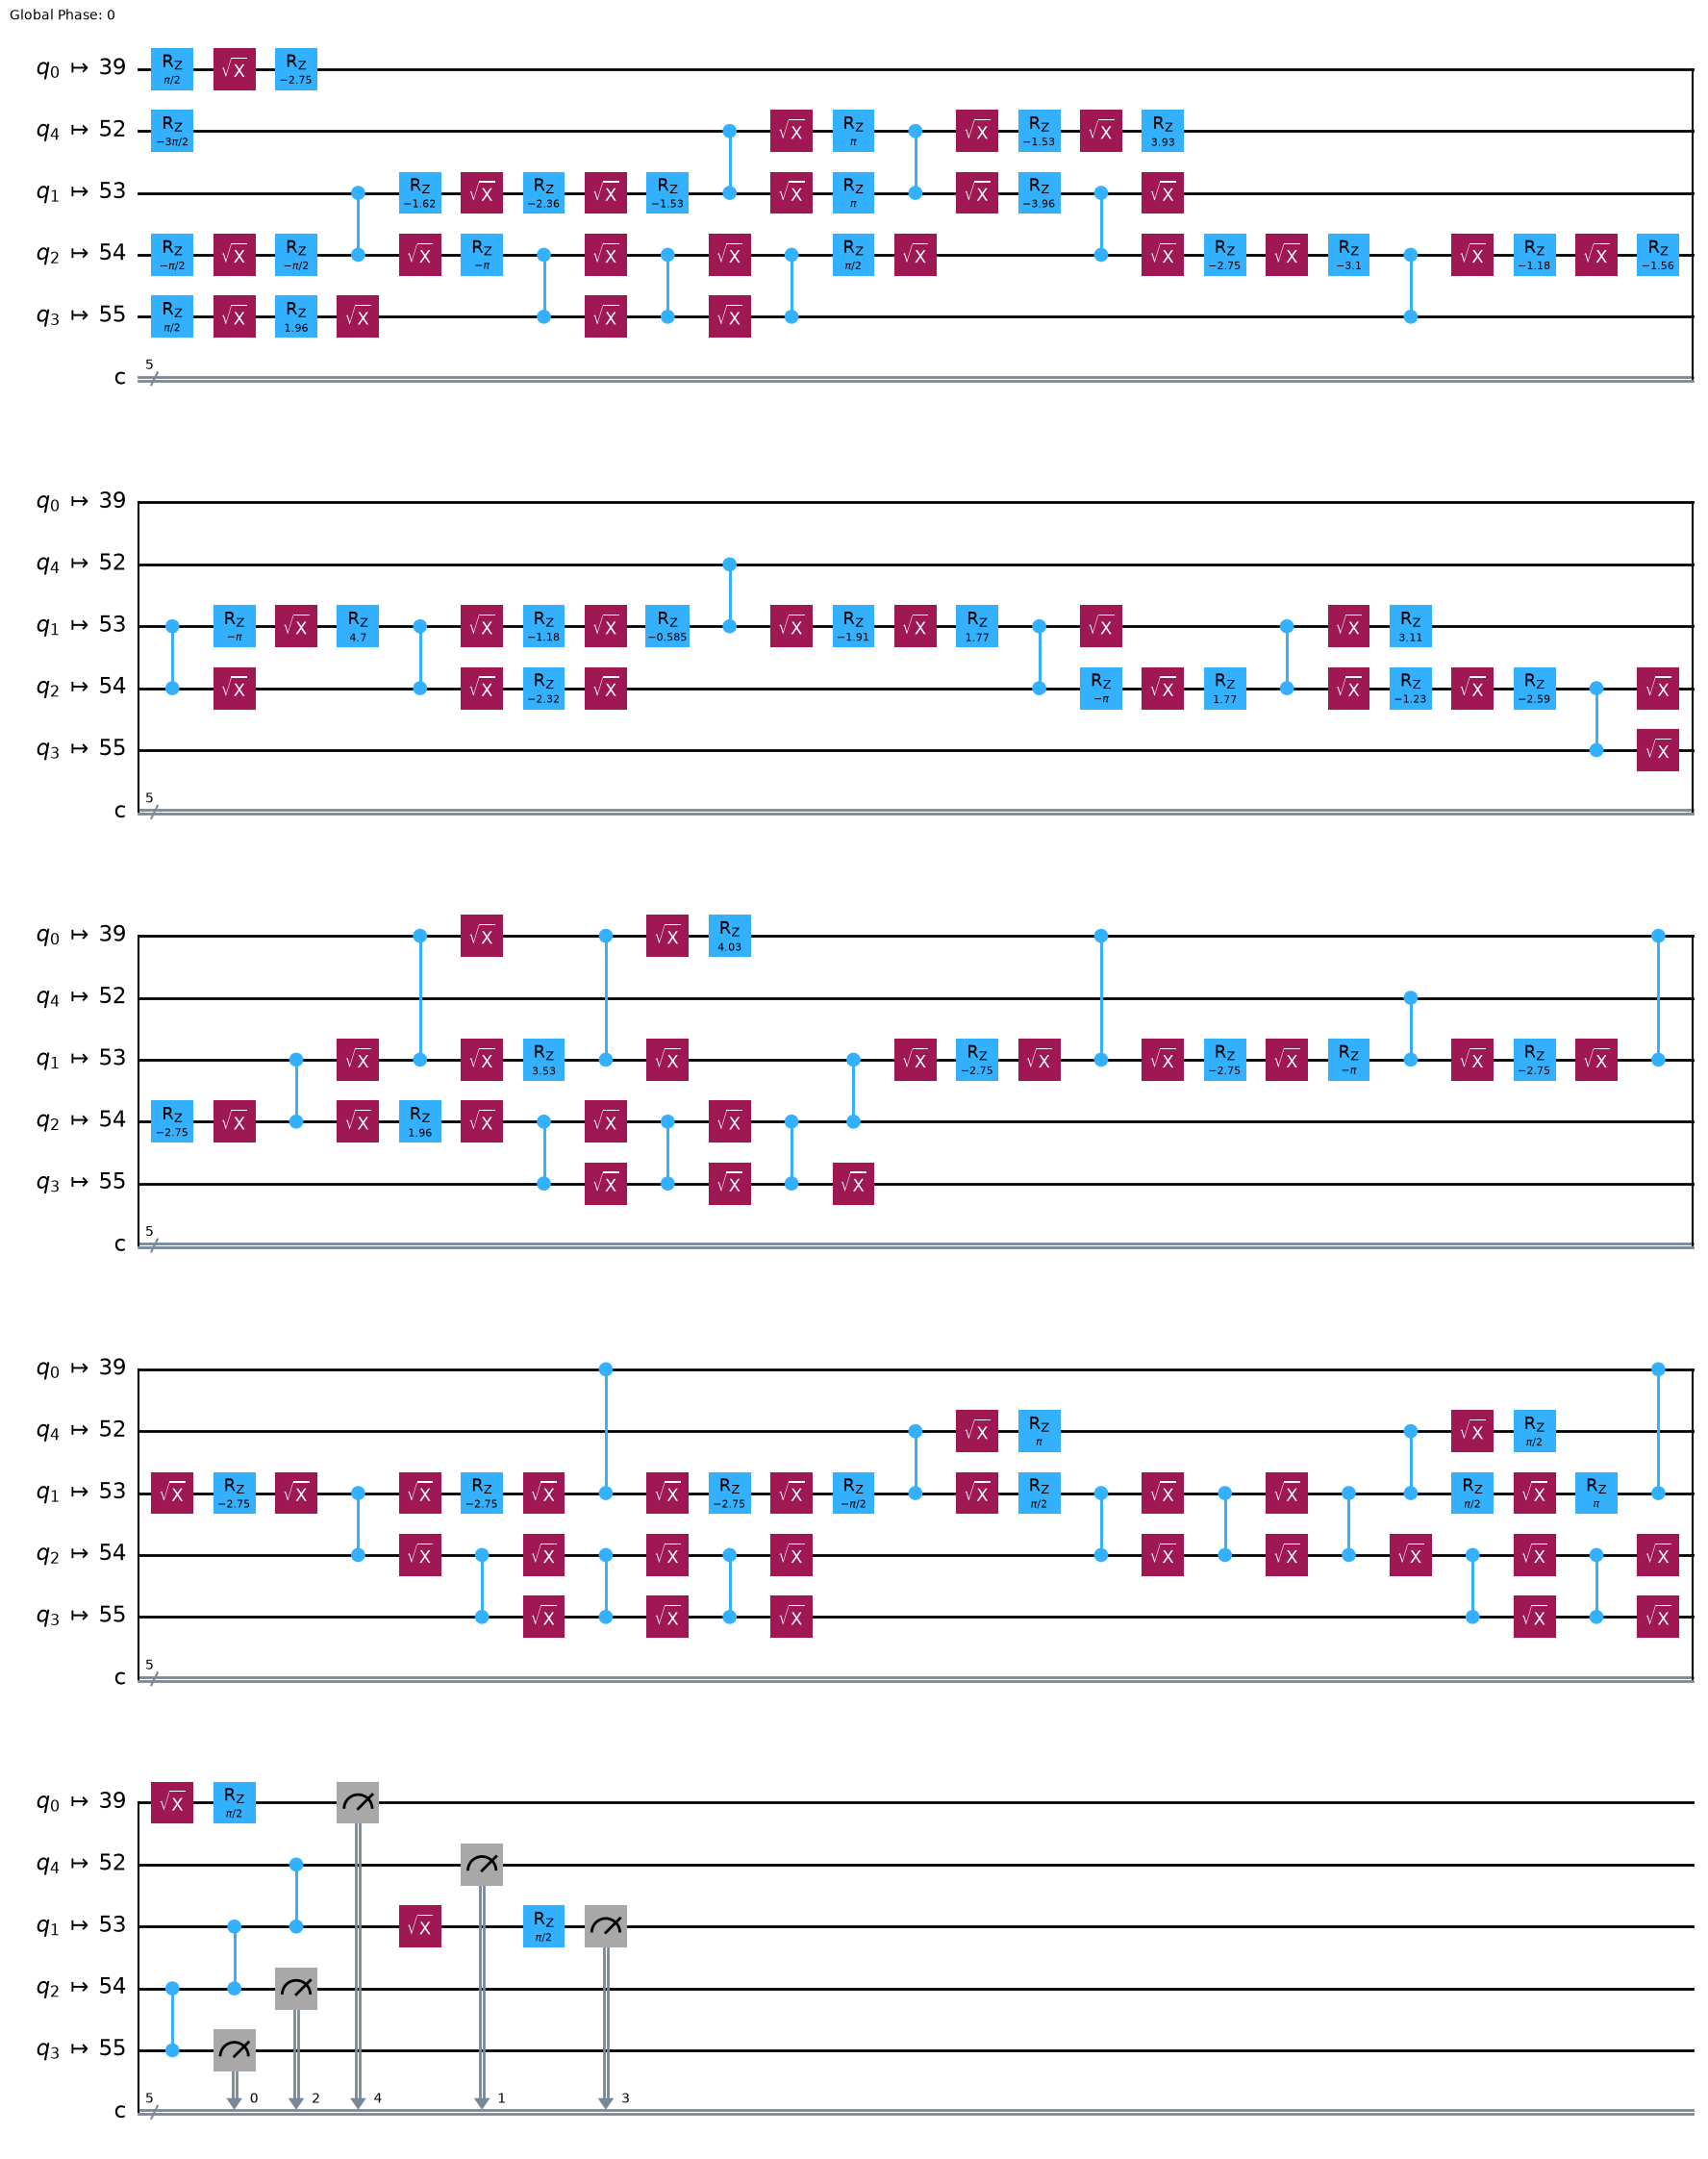

In [227]:
qc_transpiled = 

### Step 3-3. Run the transpiled circut
We choose a sampler again, and run the circuit on it.

In [229]:
from qiskit_ibm_runtime.executor_sampler import Sampler


In [230]:
job_qpu = 

### Step 3-4. Check the status

In [234]:
job_id_qpu = job_qpu.job_id()
job_status_qpu = job_qpu.status()
print("Job ID: ", job_id_qpu)
print("Job Status: ", job_status_qpu)

Job ID:  db1iigqvog1s73fi5vrg
Job Status:  QUEUED


### Step 3-5. Retrieve the result data

In [232]:
job_qpu = 
result_qpu = 

KeyboardInterrupt: 

### Step 3-6. Check the counts

In [ ]:
measure_all = 'meas' in dir(result_qpu[0].data)
measure_c = 'c' in dir(result_qpu[0].data)

counts_qpu = None
if measure_all:
    # When using measure all
    counts_qpu = result_qpu[0].data.meas.get_counts()
elif measure_c:
    # in our method
    counts_qpu = result_qpu[0].data.c.get_counts()
counts_qpu

### Step 3-7. Plot it on the Patoka result dashboard

In [ ]:
viewer_real = getResultViewer()

In [ ]:
display(viewer_real)

In [ ]:
job_data = processJobData(service, job_id_qpu, q)
job_data.streamJSON(viewer_real) # this pattern is adopted because of a large volume.